# Water boiling temperature vs elevation: reference table demo

**Question.** How well does a simple barometric formula predict the boiling point of water at different altitudes, compared with published measurements?

**What this artifact is.** A small, schema-checked reference table of the boiling temperature of water from 0 to 4000 m in 100 m steps (41 rows). Every row is **equation-derived**: the values come from a barometric-levelling table (deleze.name), not from field measurements. The measured-site count is therefore **zero**, and the planned holdout set is empty.

**What this notebook does.** It reruns the original `data.py` steps on the demo data: rebuild each row, check the example format, build the dataset metadata, make the mini and preview variants, then plot the table against the formula. It runs on CPU in seconds.

**Caveat.** Agreement between the formula and this table shows that two calculations are consistent with each other. It does **not** test the formula against measurements, which the hypothesis needs and this release does not provide.


In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# Only matplotlib is needed beyond the standard library; it is pre-installed on Colab.
if 'google.colab' not in sys.modules:
    _pip('matplotlib==3.10.0')


In [2]:
# Original data.py imports (the __future__ import stays first in the cell).
from __future__ import annotations

import json
from pathlib import Path

import matplotlib.pyplot as plt

# One colour per role, the same in every notebook of this run and in the paper's figures.
COLOURS = {
    "method": "#0173B2",  # the paper's own method, model or condition
    "baseline": "#949494",  # the main baseline, control or reference
    "other_1": "#DE8F05",  # the first further comparator
    "other_2": "#029E73",  # the second
    "other_3": "#CC78BC",  # the third
    "other_4": "#CA9161",  # the fourth
    "other_5": "#56B4E9",  # the fifth
}
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["CMU Serif", "Computer Modern Roman", "DejaVu Serif"],
    "mathtext.fontset": "cm",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#CCCCCC",
    "grid.alpha": 0.6,
    "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=list(COLOURS.values())),
    "image.cmap": "cividis",
    "legend.frameon": False,
    "figure.constrained_layout.use": True,
    "figure.dpi": 120,
})


## Data loading

The notebook loads `mini_demo_data.json` from GitHub. If the network is unavailable, it falls back to the local copy in this folder. The demo file holds all 41 rows of the reference table.


In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-afc680-barometric-formula-predicts-waters/main/round-1/dataset-1/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")


In [4]:
data = load_data()
print("dataset groups:", len(data["datasets"]), "| examples:", sum(len(d["examples"]) for d in data["datasets"]))


GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
dataset groups: 1 | examples: 41


## Config

The values the demo uses. The original script's values are in the comments. The demo is already at full size, so a full run keeps every row.


In [5]:
N_MINI = 3            # examples kept per dataset in the mini file (original script: 3)
TRUNCATE_CHARS = 200  # string cap for the preview file (original script: 200)
# Set N_MINI = 41 to keep every row; the demo file already holds all 41 rows.


## Step 1: Example format

`to_example` maps one table row to one example. The **input** is the elevation only; the formula and table values are withheld so the input does not leak the target. The **output** is the table boiling temperature as a string.

The demo file already holds these examples. The cell below rebuilds each source row from the example fields, runs `to_example` on it, and checks that the result matches the file exactly.


In [6]:
DATASET_NAME = "boiling_point_altitude_reference_grid"


def to_example(rec: dict, i_row: int) -> dict:
    return {
        "input": json.dumps({"elevation_m": rec["elevation_m"]}, sort_keys=True),
        "output": f"{rec['boiling_temp_C']:.1f}",
        "metadata_site_id": rec["site_id"],
        "metadata_evidence_type": rec["evidence_type"],
        "metadata_split": rec["split"],
        "metadata_altitude_band": rec["altitude_band"],
        "metadata_boiling_temp_uncertainty_C": rec["boiling_temp_uncertainty_C"],
        "metadata_formula_boiling_C": rec["formula_boiling_C"],
        "metadata_formula_residual_C": rec["formula_residual_C"],
        "metadata_source_citation": rec["source_citation"],
        "metadata_row_index": i_row,
    }


# Rebuild the source records from the loaded examples (the inverse of to_example).
examples = data["datasets"][0]["examples"]
records = [
    {
        "elevation_m": json.loads(ex["input"])["elevation_m"],
        "boiling_temp_C": float(ex["output"]),
        "site_id": ex["metadata_site_id"],
        "evidence_type": ex["metadata_evidence_type"],
        "split": ex["metadata_split"],
        "altitude_band": ex["metadata_altitude_band"],
        "boiling_temp_uncertainty_C": ex["metadata_boiling_temp_uncertainty_C"],
        "formula_boiling_C": ex["metadata_formula_boiling_C"],
        "formula_residual_C": ex["metadata_formula_residual_C"],
        "source_citation": ex["metadata_source_citation"],
    }
    for ex in examples
]
rebuilt = [to_example(rec, i) for i, rec in enumerate(records)]
print("round-trip matches the demo file:", rebuilt == examples, "| rows:", len(rebuilt))


round-trip matches the demo file: True | rows: 41


## Step 2: Metadata and full dataset

`build` wraps all examples into one dataset group and attaches the metadata: the description, the predefined holdout rule, and `measured_site_count = 0`.


In [7]:
def build(records: list[dict]) -> dict:
    examples = [to_example(rec, i) for i, rec in enumerate(records)]
    return {
        "metadata": {
            "description": "Boiling temperature of water vs elevation; equation-derived reference grid. "
            "No measured sites verified; measured_site_count = 0.",
            "holdout_rule": "Predefined: hold out measured sites in the Americas above 1000 m. Empty in this release.",
            "measured_site_count": 0,
        },
        "datasets": [{"dataset": DATASET_NAME, "examples": examples}],
    }


full = build(records)
print("measured_site_count:", full["metadata"]["measured_site_count"])
print("matches the loaded demo data:", full == data)


measured_site_count: 0
matches the loaded demo data: True


## Step 3: Mini and preview variants

The mini variant keeps the first `N_MINI` examples per dataset. The preview variant is the mini variant with every string cut to `TRUNCATE_CHARS` characters. The original script wrote these to disk; the notebook keeps them in memory for display.


In [8]:
def truncate(obj):
    if isinstance(obj, str):
        return obj[:TRUNCATE_CHARS]
    if isinstance(obj, list):
        return [truncate(x) for x in obj]
    if isinstance(obj, dict):
        return {k: truncate(v) for k, v in obj.items()}
    return obj


mini = {
    **{k: v for k, v in full.items() if k != "datasets"},
    "datasets": [{"dataset": d["dataset"], "examples": d["examples"][:N_MINI]} for d in full["datasets"]],
}
preview = truncate(mini)
n = sum(len(d["examples"]) for d in full["datasets"])
print(f"built {n} examples across {len(full['datasets'])} dataset group(s)")
print(f"mini: {sum(len(d['examples']) for d in mini['datasets'])} examples; preview strings capped at {TRUNCATE_CHARS} characters")


built 41 examples across 1 dataset group(s)
mini: 3 examples; preview strings capped at 200 characters


## Results: reference table against the barometric formula

The table below lists every row. `residual = formula - table`, so a positive residual means the formula predicts a higher boiling point than the table.


In [9]:
rows = full["datasets"][0]["examples"]
elev = [json.loads(r["input"])["elevation_m"] for r in rows]
table = [float(r["output"]) for r in rows]
formula = [r["metadata_formula_boiling_C"] for r in rows]
resid = [r["metadata_formula_residual_C"] for r in rows]

print(f"{'elev (m)':>9} {'table (C)':>10} {'formula (C)':>12} {'residual (C)':>13}")
for e, t, f, r in zip(elev, table, formula, resid):
    print(f"{e:9.0f} {t:10.1f} {f:12.2f} {r:13.2f}")
print(f"\nresidual mean: {sum(resid)/len(resid):.3f} C, max |residual|: {max(abs(r) for r in resid):.2f} C")


 elev (m)  table (C)  formula (C)  residual (C)
        0      100.0       100.01          0.01
      100       99.7        99.68         -0.02
      200       99.3        99.36          0.06
      300       99.0        99.03          0.03
      400       98.7        98.70          0.00
      500       98.3        98.38          0.08
      600       98.0        98.05          0.05
      700       97.7        97.72          0.02
      800       97.3        97.39          0.09
      900       97.0        97.06          0.06
     1000       96.7        96.73          0.03
     1100       96.3        96.40          0.10
     1200       96.0        96.07          0.07
     1300       95.7        95.73          0.03
     1400       95.3        95.40          0.10
     1500       95.0        95.06          0.06
     1600       94.7        94.73          0.03
     1700       94.3        94.39          0.09
     1800       94.0        94.05          0.05
     1900       93.7        93.72       

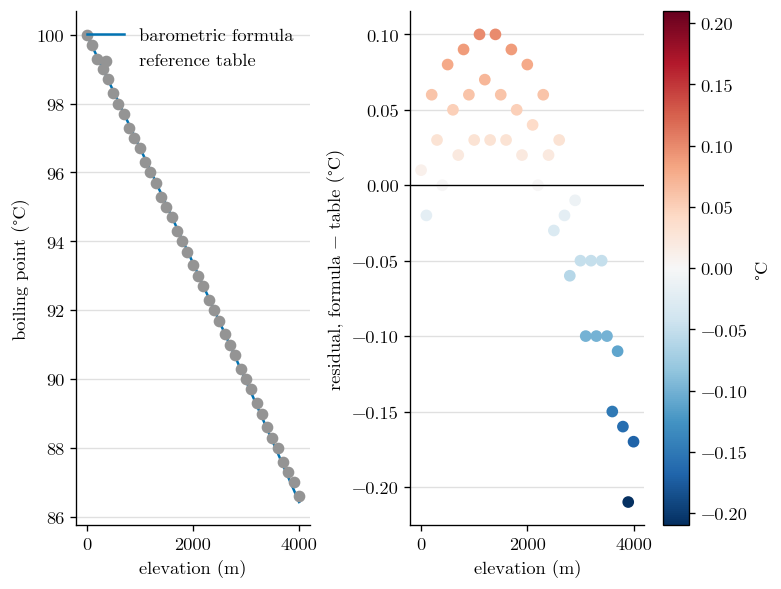

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2)
# Left: the reference table (baseline) against the barometric formula (method).
ax1.plot(elev, formula, color=COLOURS["method"], label="barometric formula")
ax1.scatter(elev, table, color=COLOURS["baseline"], label="reference table", zorder=3)
ax1.set_xlabel("elevation (m)")
ax1.set_ylabel("boiling point (°C)")
ax1.legend()
# Right: signed residuals (formula minus table) on a diverging colour map.
lim = max(abs(r) for r in resid)
sc = ax2.scatter(elev, resid, c=resid, cmap="RdBu_r", vmin=-lim, vmax=lim)
ax2.axhline(0, color="black", lw=0.8)
ax2.set_xlabel("elevation (m)")
ax2.set_ylabel("residual, formula − table (°C)")
fig.colorbar(sc, ax=ax2, label="°C")
plt.show()


## Interpreting the results

- The formula and the reference table agree closely over 0 to 4000 m. The mean residual is -0.004 °C, and the largest absolute residual is 0.21 °C.
- The residuals are not flat. They are mostly small and positive from about 1000 to 2500 m, then drift negative above about 3000 m, reaching -0.21 °C near 3900 m. The 0.21 °C maximum is larger than the 0.05 °C per-row table uncertainty in the metadata, so the formula and table are not identical at high altitude.
- **This does not test the formula against measurements.** Every row is equation-derived, and the measured-site count is zero. The hypothesis needs measured boiling records at named sites with pressure and thermometer uncertainty. This demo cannot answer that part of the question.
